In [2]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd

In [3]:
with open('../data/battery/632c6db3__monthly_revs_1.0h_1.0cyc_88%RTE_GB_London_Distribution_Central scenario_Ancillaries focus.csv') as f:
    for i in range(30):
        print(f"{i+1:02d}:", f.readline().rstrip())


01: ﻿Created at:,2025-07-10 19:35
02: Strategy:,Ancillaries focus
03: Rated Power:,50.0 MW
04: Duration:,1.0h
05: Efficiency:,88%
06: Max Daily Cycles:,1.0
07: Start Date:,2025-01-01
08: Degradation:,Disabled
09: Region:,London
10: Generation Zone:,Central London
11: Connection Type:,Distribution
12: Max Import:,50.0 MW
13: Max Export:,50.0 MW
14: Model Version:,v3.5
15: Macro Scenario:,Central scenario
16: Scenario Databook:,https://forecasts-modoenergy-prod.s3.eu-west-2.amazonaws.com/fundamental_model_outputs/v3.5/Central+scenario/Scenario_Databook%3A_Central_scenario.csv
17: These are Real 2023 values
18: 
19: 
20: 
21: 
22: Month,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01,2026-10-01,2026-11-01,2026-12-01,2027-01-01,2027-02-01,2027-03-01,2027-04-01,2027-05-01,2027-06-01,2027-07-01,2027-08-01,2027-0

In [64]:
battery_ancillary = pd.read_csv(
    "../data/battery/632c6db3__monthly_revs_1.0h_1.0cyc_88%RTE_GB_London_Distribution_Central scenario_Ancillaries focus.csv",
    skiprows=21,
    index_col=0, thousands=','
)
battery_ancillary.dropna(how='all', inplace=True)
battery_ancillary = battery_ancillary.T
battery_ancillary.drop_duplicates()
battery_ancillary.drop(columns= 'Year', inplace =True)
battery_ancillary = battery_ancillary.loc[:, ~battery_ancillary.columns.duplicated()]
battery_ancillary.index = pd.to_datetime(battery_ancillary.index)
battery_ancillary

Month,Avg. Cycles per day,Avg. Battery State Of Health (%),Avg. Wholesale Day Ahead Price (£/MWh),Wholesale Day Ahead Total Revenues (£/MW/month),Wholesale Intraday Revenues (£/MW/month),Balancing Mechanism Revenues (£/MW/month),Frequency Response Revenues (£/MW/month),Balancing Reserve Revenues (£/MW/month),Capacity Market Revenues (£/MW/month),TNUoS Revenues (£/MW/month),Total Revenues (£/MW/month),Wholesale Day Ahead Total Revenues (£/MW/year),Wholesale Intraday Revenues (£/MW/year),Balancing Mechanism Revenues (£/MW/year),Frequency Response Revenues (£/MW/year),Balancing Reserve Revenues (£/MW/year),Capacity Market Revenues (£/MW/year),TNUoS Revenues (£/MW/year),Total Revenues (£/MW/year)
2025-01-01,1.0,100.0,86.73,2018.94,-741.60,3852.61,304.11,0.0,480.85,151.14,6066.06,16659.47,-2188.48,32050.49,4286.10,0.0,5661.65,2854.04,59323.28
2025-02-01,1.0,100.0,89.71,1810.85,-427.79,3318.36,268.78,0.0,434.32,136.51,5541.03,16613.14,-2893.40,31636.70,4024.45,0.0,7223.75,3595.72,60200.36
2025-03-01,1.0,100.0,80.59,1685.46,-132.47,3044.16,332.00,0.0,480.85,151.14,5561.14,14310.78,-3730.13,29614.96,2981.36,0.0,7683.70,3875.38,54736.04
2025-04-01,1.0,100.0,64.17,982.40,95.77,2192.76,349.42,0.0,465.34,263.48,4349.17,13072.10,-3404.32,31243.14,2686.86,0.0,5223.33,3869.79,52690.90
2025-05-01,1.0,100.0,58.42,962.07,-43.08,2050.20,394.91,0.0,480.85,272.26,4117.22,13693.17,-3219.73,29474.32,2798.87,0.0,5983.46,4230.56,52960.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2049-08-01,1.0,100.0,33.08,1285.52,-106.57,1439.75,275.65,0.0,38.65,370.24,3303.24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2049-09-01,1.0,100.0,15.34,1029.45,-309.47,1275.95,309.64,0.0,37.40,358.29,2701.27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2049-10-01,1.0,100.0,26.17,1256.29,147.95,1339.67,298.00,0.0,38.65,370.24,3450.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2049-11-01,1.0,100.0,37.01,1199.21,-156.98,2258.00,280.47,0.0,37.40,358.29,3976.39,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [59]:
battery_ancillary.columns

Index(['Avg. Cycles per day', 'Avg. Battery State Of Health (%)',
       'Avg. Wholesale Day Ahead Price (£/MWh)',
       'Wholesale Day Ahead Total Revenues (£/MW/month)',
       'Wholesale Intraday Revenues (£/MW/month)',
       'Balancing Mechanism Revenues (£/MW/month)',
       'Frequency Response Revenues (£/MW/month)',
       'Balancing Reserve Revenues (£/MW/month)',
       'Capacity Market Revenues (£/MW/month)', 'TNUoS Revenues (£/MW/month)',
       'Total Revenues (£/MW/month)',
       'Wholesale Day Ahead Total Revenues (£/MW/year)',
       'Wholesale Intraday Revenues (£/MW/year)',
       'Balancing Mechanism Revenues (£/MW/year)',
       'Frequency Response Revenues (£/MW/year)',
       'Balancing Reserve Revenues (£/MW/year)',
       'Capacity Market Revenues (£/MW/year)', 'TNUoS Revenues (£/MW/year)',
       'Total Revenues (£/MW/year)'],
      dtype='object', name='Month')

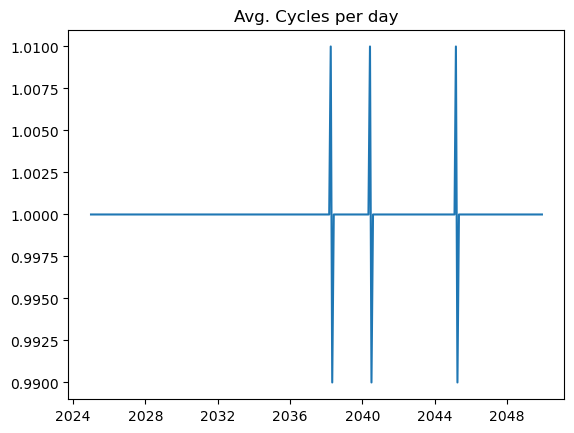

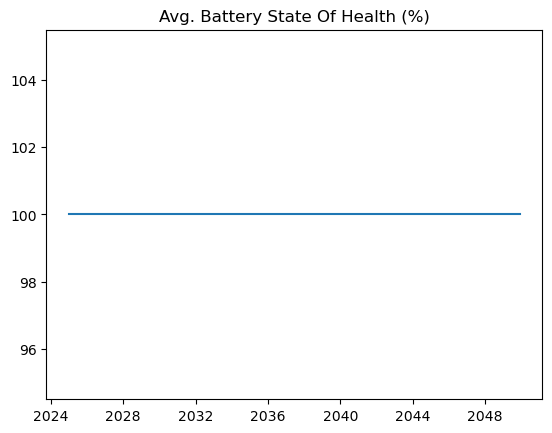

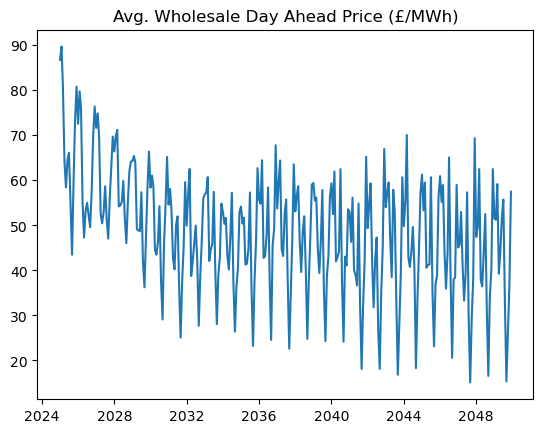

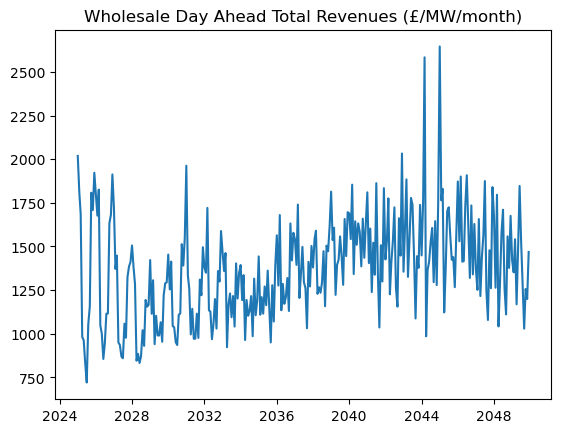

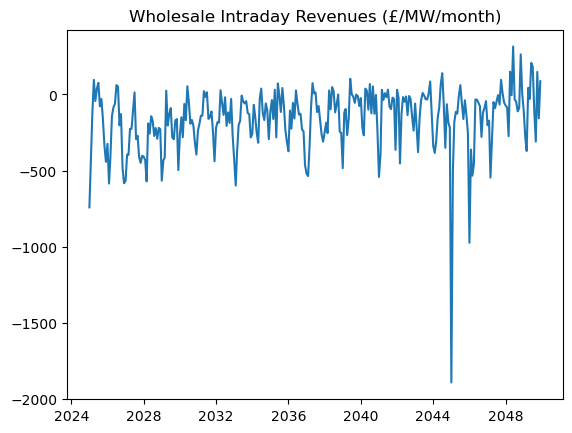

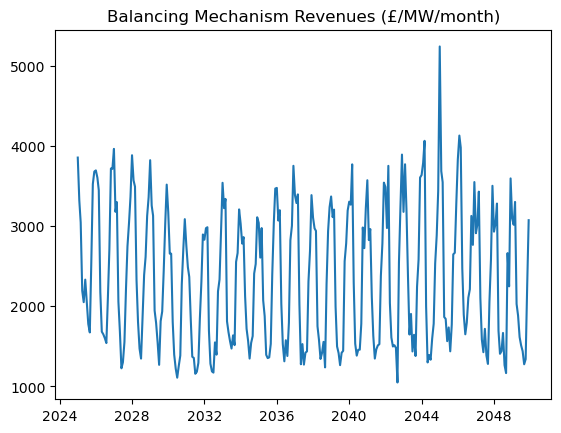

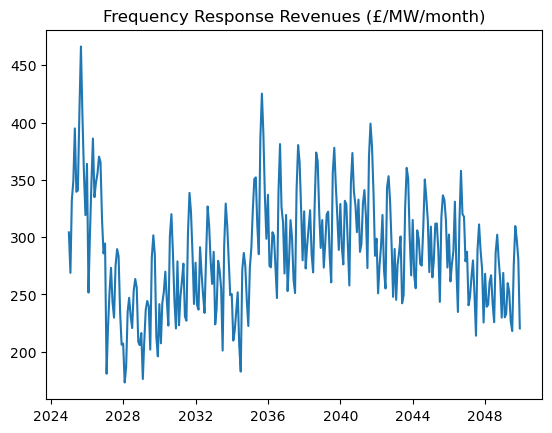

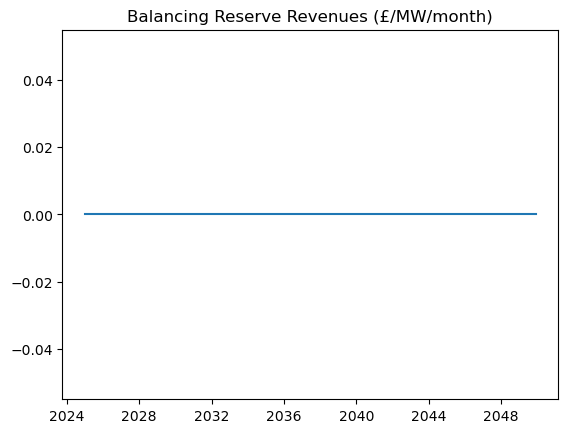

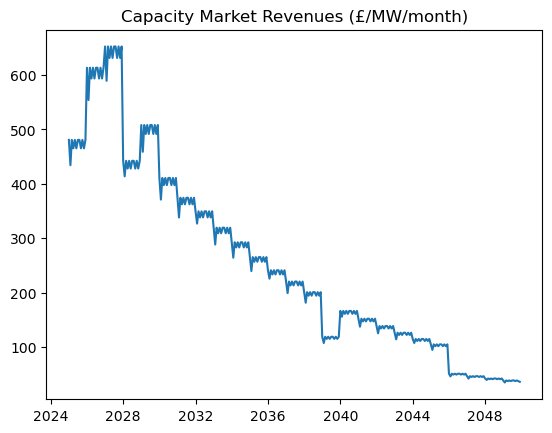

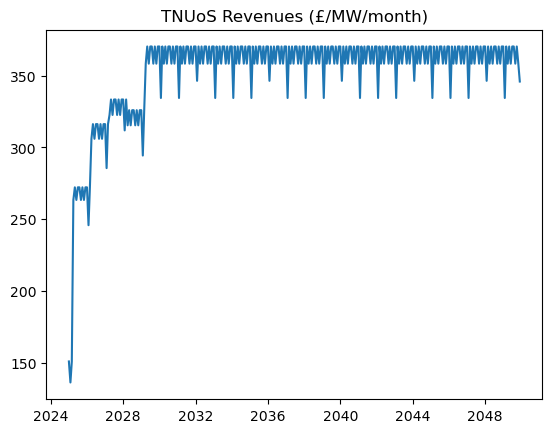

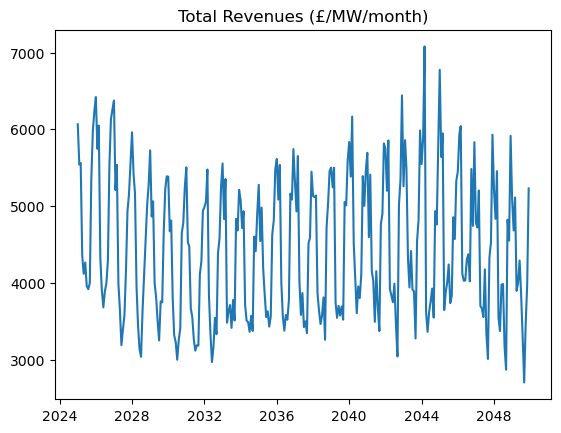

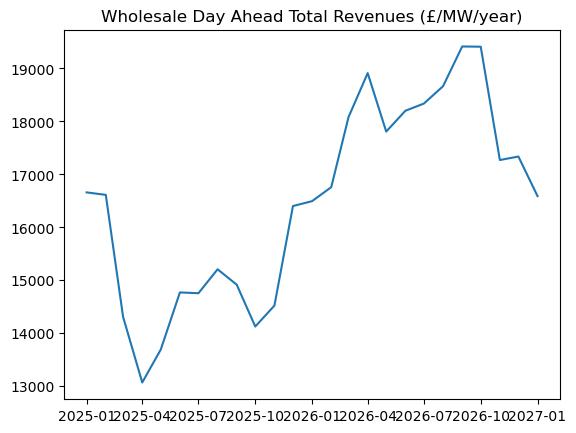

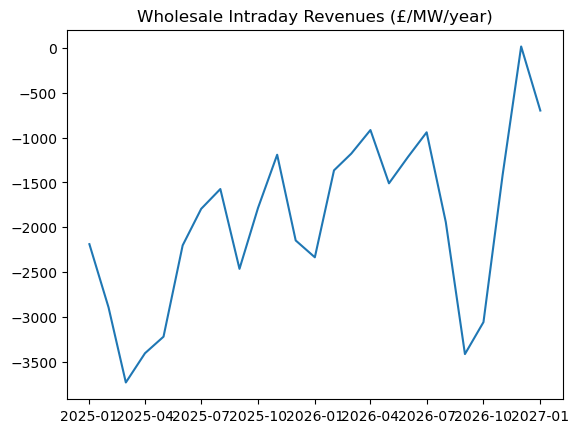

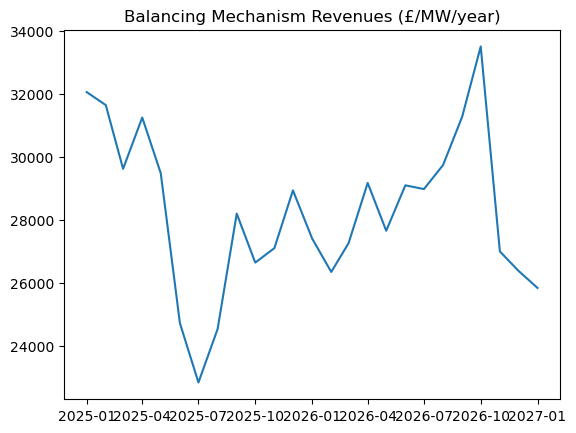

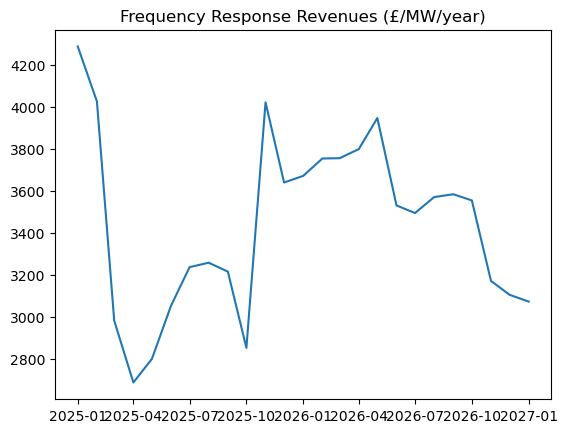

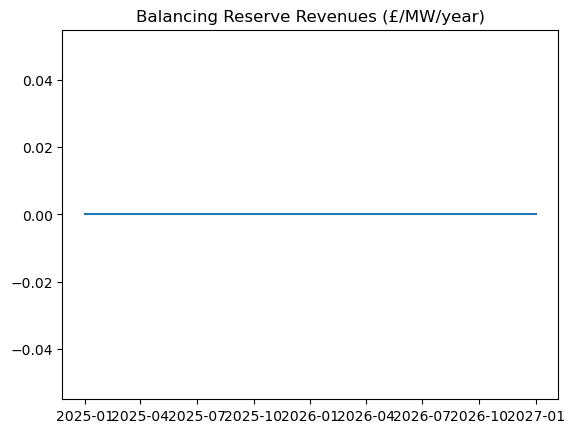

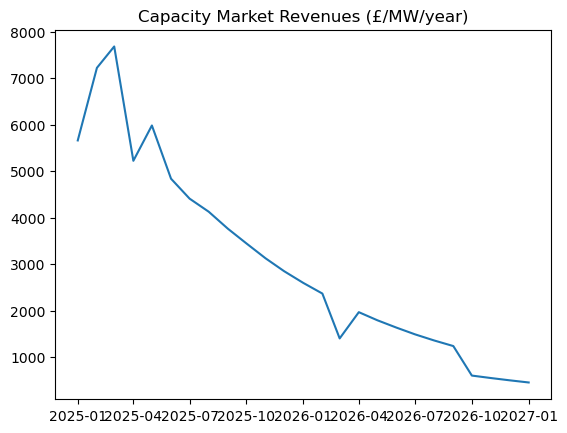

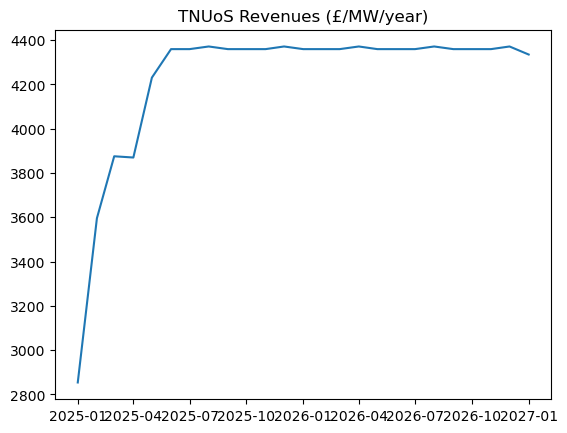

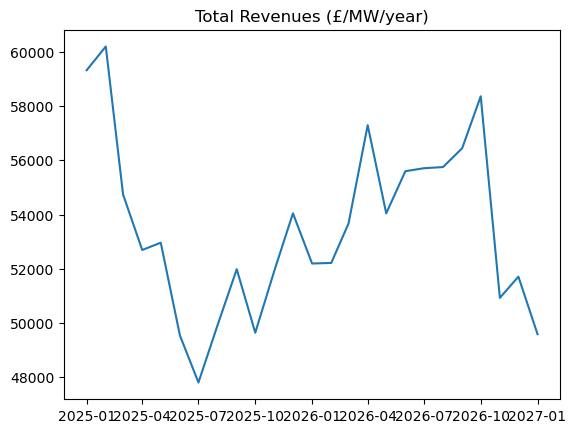

In [65]:
for col in battery_ancillary.columns:
    plt.plot(battery_ancillary[col])
    plt.title(col)
    plt.show()

In [62]:
battery_merchant = pd.read_csv(
    "../data/battery/a8f6b55f__monthly_revs_1.0h_1.0cyc_88%RTE_GB_London_Distribution_Central scenario_Merchant focus.csv",
    skiprows=21,
    index_col=0, thousands=','
)
battery_merchant.dropna(how='all', inplace=True)
battery_merchant = battery_merchant.T
battery_merchant.drop_duplicates()
battery_merchant.drop(columns= 'Year', inplace =True)
battery_merchant = battery_merchant.loc[:, ~battery_merchant.columns.duplicated()]
battery_merchant.index = pd.to_datetime(battery_merchant.index)
battery_merchant

Month,Avg. Cycles per day,Avg. Battery State Of Health (%),Avg. Wholesale Day Ahead Price (£/MWh),Wholesale Day Ahead Total Revenues (£/MW/month),Wholesale Intraday Revenues (£/MW/month),Balancing Mechanism Revenues (£/MW/month),Frequency Response Revenues (£/MW/month),Balancing Reserve Revenues (£/MW/month),Capacity Market Revenues (£/MW/month),TNUoS Revenues (£/MW/month),Total Revenues (£/MW/month),Wholesale Day Ahead Total Revenues (£/MW/year),Wholesale Intraday Revenues (£/MW/year),Balancing Mechanism Revenues (£/MW/year),Frequency Response Revenues (£/MW/year),Balancing Reserve Revenues (£/MW/year),Capacity Market Revenues (£/MW/year),TNUoS Revenues (£/MW/year),Total Revenues (£/MW/year)
2025-01-01,1.0,100.0,86.73,2098.75,-1021.29,3776.03,0.0,1.04,480.85,151.14,5486.52,17278.64,-4646.81,31406.39,0.0,2.60,5661.65,2854.04,52556.50
2025-02-01,1.0,100.0,89.71,1882.32,-585.61,3174.46,0.0,0.52,434.32,136.51,5042.53,17156.18,-4719.91,31222.54,0.0,1.38,7223.75,3595.72,54479.65
2025-03-01,1.0,100.0,80.59,1739.28,-313.51,2979.44,0.0,0.52,480.85,151.14,5037.72,14580.09,-5019.31,29644.40,0.0,0.00,7683.70,3875.38,50764.26
2025-04-01,1.0,100.0,64.17,1008.93,-96.94,2169.23,0.0,0.00,465.34,263.48,3810.04,13368.00,-4298.69,30921.63,0.0,0.35,5223.33,3869.79,49084.41
2025-05-01,1.0,100.0,58.42,1004.75,-143.65,1991.16,0.0,0.00,480.85,272.26,3605.37,13946.06,-4036.53,29428.78,0.0,0.00,5983.46,4230.56,49552.32
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2049-08-01,1.0,100.0,33.08,1311.27,-144.09,1447.98,0.0,0.00,38.65,370.24,3024.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2049-09-01,1.0,100.0,15.34,1052.91,-334.37,1265.18,0.0,0.00,37.40,358.29,2379.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2049-10-01,1.0,100.0,26.17,1279.65,146.69,1327.60,0.0,0.00,38.65,370.24,3162.83,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2049-11-01,1.0,100.0,37.01,1227.10,-215.11,2217.62,0.0,0.00,37.40,358.29,3625.29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


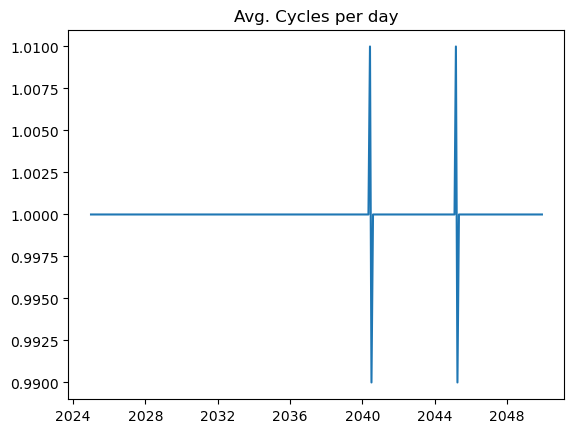

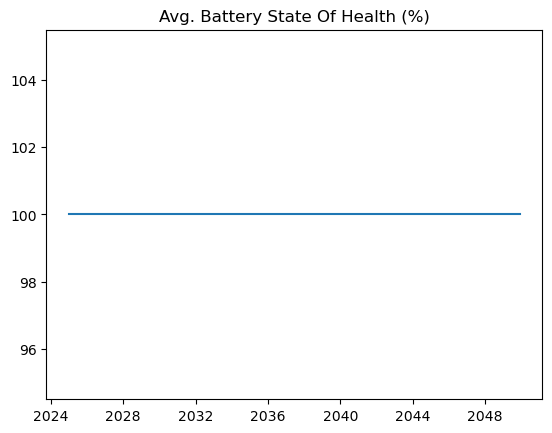

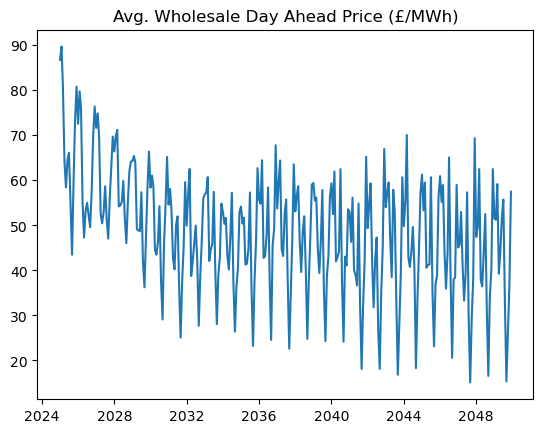

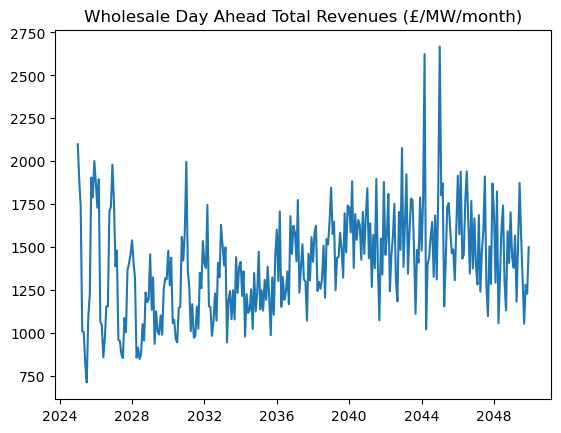

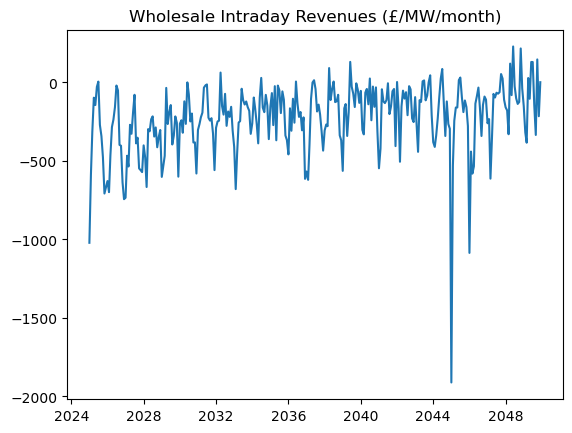

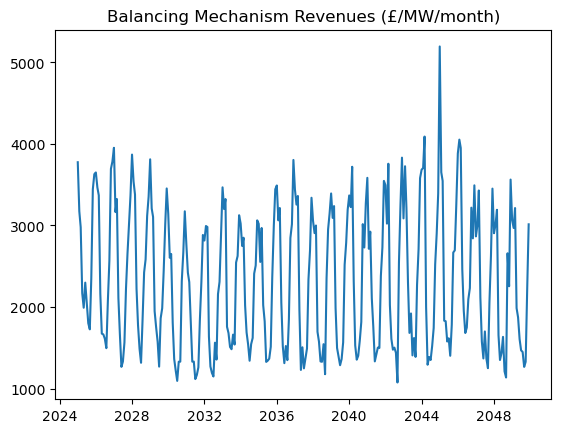

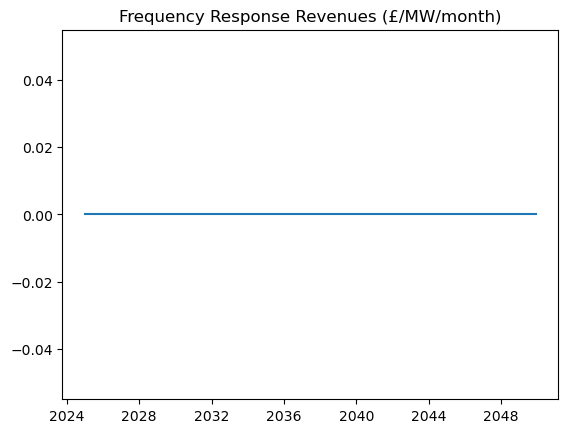

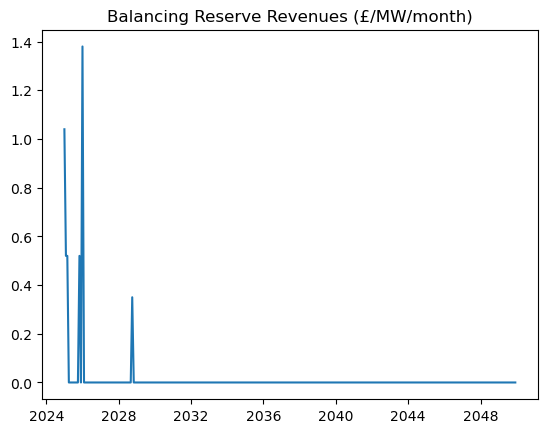

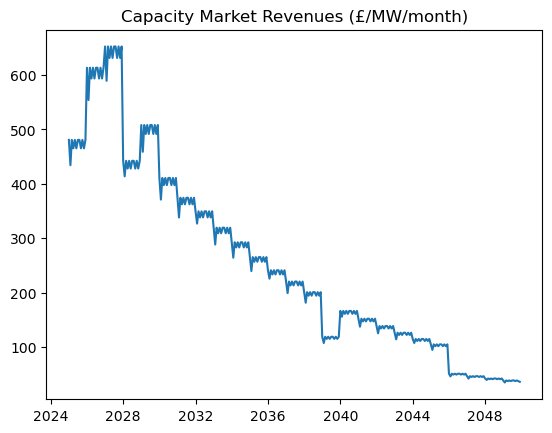

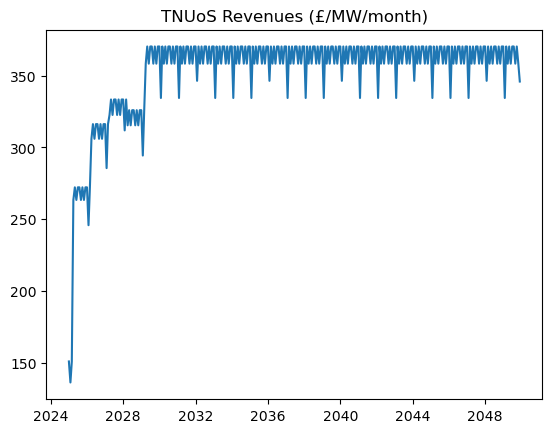

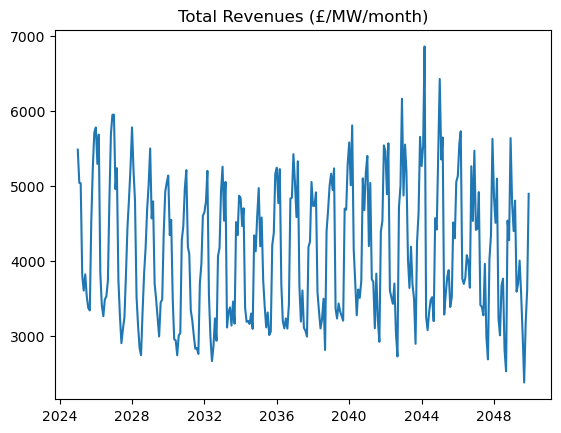

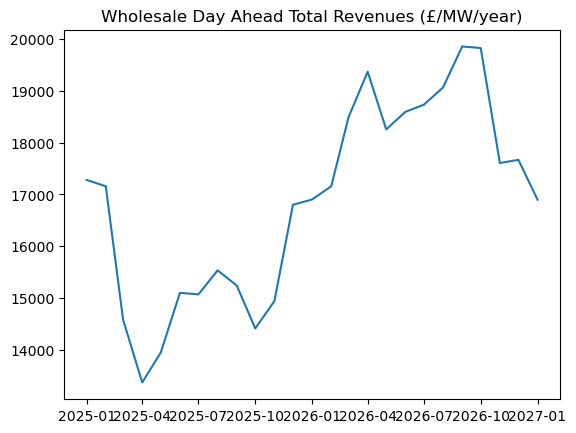

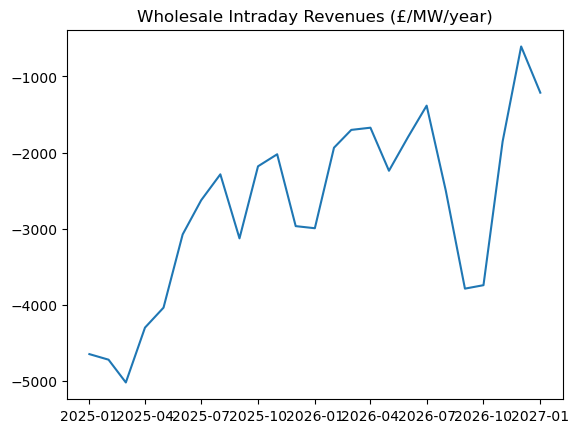

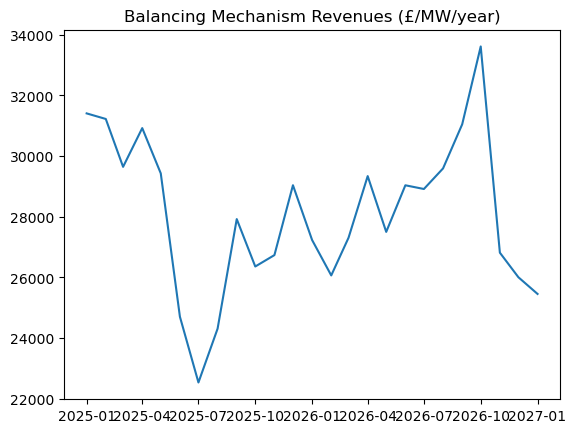

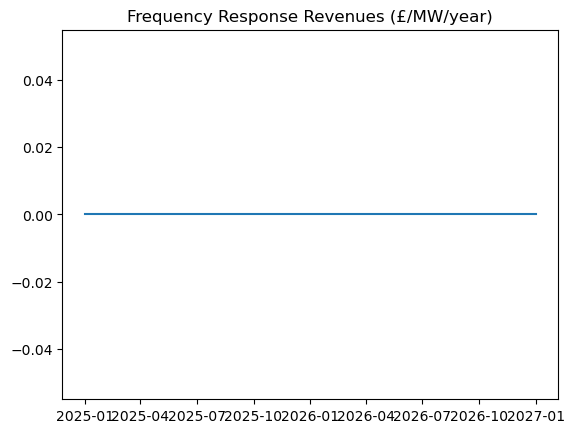

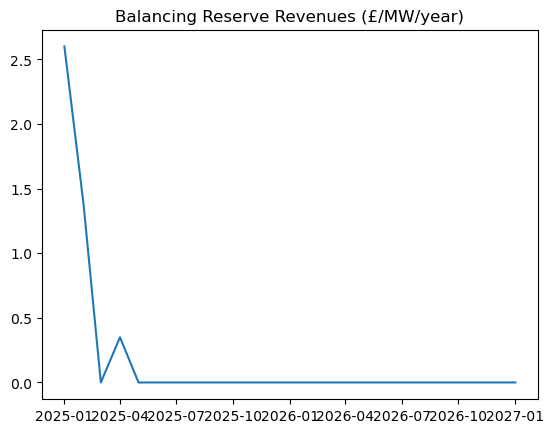

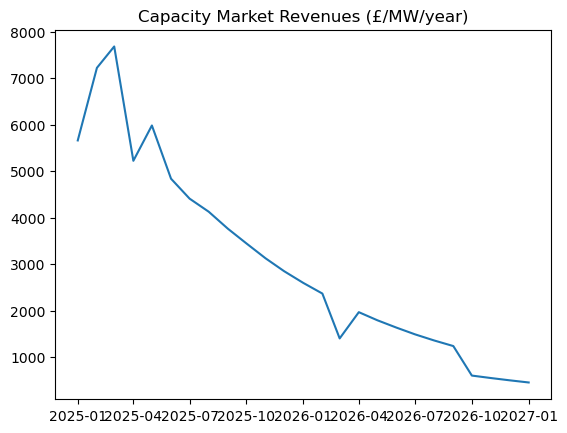

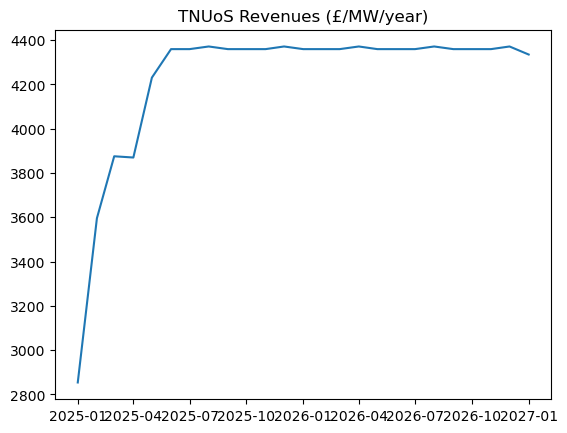

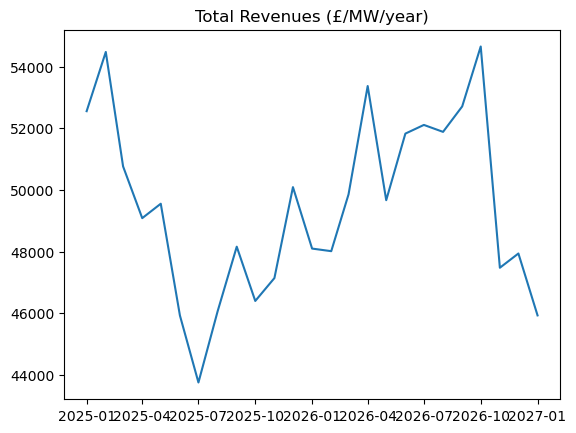

In [63]:
for col in battery_merchant.columns:
    plt.plot(battery_merchant[col])
    plt.title(col)
    plt.show()